=============================================================================

### NOTE: Computing SHAP and permutation importance (PI) feature importances
 

=============================================================================

Best practice is to calculate SHAP values and permutation importance on
HELD-OUT test data (rows the model was not fitted on). A random forest can
nearly memorise its training data, so importances computed on training rows
mostly describe what the model memorised rather than what generalises.
(PI in particular needs held-out data to measure the loss in predictive skill.)

There are three ways to set this up, in increasing order of robustness and
compute cost:

1. Single train/test split (simplest, fastest)
   Fit the model on the training set, then compute SHAP and PI on the test
   set. Gives one importance estimate per variable, from one split, so it
   can be sensitive to which rows happen to land in the test set. Only
   test-set rows get SHAP values.

2. K-fold cross-validation (more robust, slower)
   Fit a fresh model on each training fold and compute SHAP and PI on the
   matching held-out fold. Every row gets one out-of-fold SHAP value, and
   the spread of PI/SHAP across folds shows how stable the ranking is.
   Cost: roughly K model fits, K SHAP runs and K PI runs.

3. Repeated k-fold cross-validation (most robust, slowest)
   Repeat the k-fold procedure with different random splits and average
   across repeats. Shows how sensitive the importances are to the choice of
   split, and gives each row several out-of-fold SHAP values. Cost: roughly
   (repeats x K) fits, SHAP runs and PI runs.

COMPUTE TIME: options 2 and 3 can take a long time on large datasets
(SHAP in particular). Ways to reduce it: constrain the forest
(e.g. max_depth, min_samples_leaf), explain a subsample of each test fold,
use n_jobs for PI, parallelise repeats with joblib, and start with a small
number of repeats (e.g. 3) before scaling up.


=============================================================================

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 
from sklearn.model_selection import (KFold, cross_validate, cross_val_predict, train_test_split)
from scipy.stats import spearmanr
import shap
import time

TARGET = "prop_floodable_area_flooded" # "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
SEED = 42

from PrepDataFunctions import *
from ModelEvaluationFunctions import *

import sys, importlib
importlib.reload(sys.modules['ModelEvaluationFunctions'])
from ModelEvaluationFunctions import *

### Prepare data

In [2]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['rainpeak_sm_day_before_onset'].notna()]
print(len(df))

# Create a proportion floodable area flooded metric
df['peak_cell_floodable_area_km2'] = df['peak_cell_floodable_area_m2']*  0.000001
df['prop_floodable_area_flooded'] = (df['rainpeak_10cm_area']/df['peak_cell_floodable_area_km2'])*100

# Get early portion of data
subset_early = create_temporal_subset(df, "before", 2020).copy()

105580


In [16]:
print(len(subset_early))
subset_early = subset_early[subset_early['length_of_active_rain']>1]
print(len(subset_early))
subset_early = subset_early[subset_early['modality']=='unimodal']
print(len(subset_early))

23526
23384
20781


In [17]:
predictor_variables = ['rainpeak_peak_value', 'rainpeak_total_precip',  
                       "hc_at_peak", 'fumax_at_peak', 
#                        "x_coord", "y_coord",
#                       'se_max', 'se_min',  'sat_at_peak_new', 'sat_at_peak_old',
#                       'fu_mean_m',  'fu_min_m', 'fu_max_m', 'fu_at_peak_new', 
                        "rainpeak_sm_day_before_onset",
         'peak_position_ratio','d50','gini','time_based_std','dry_ratio','max_quartile_index',                     
                      'peak_cell_slope_avg', 'peak_cell_elev_avg','peak_cell_elev_min','peak_cell_slope_max', 
                       #'peak_cell_inside_water_prop',
                       'peak_cell_urban_prop', 
                       #'peak_cell_inside_prop', 
                      #  'prop_floodable_area_flooded',
                     'cluster_n_cells_t50', 'cluster_n_cells_t80',
                       'max_2h', 'max_3h', 'max_6h', 'max_12h', 'max_16h',
                      'cluster_flood_10_area_t60_new','cluster_flood_10_area_t80_new',
                      "random_variable"]

X = subset_early[predictor_variables]
y = subset_early[TARGET].values

subset_early['cluster_flood_10_area_t80_new'] = subset_early['cluster_flood_10_area_t80'] - subset_early['rainpeak_10cm_area']
subset_early['cluster_flood_10_area_t60_new'] = subset_early['cluster_flood_10_area_t60'] - subset_early['rainpeak_10cm_area']

MAE: 0.704 r2: 0.800


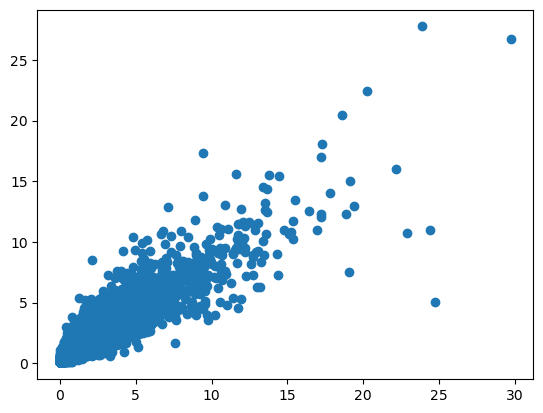

In [18]:
rf_all = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)

columns = subset_early.columns
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

rf_all.fit(X_train, y_train)
# Make predictions
y_pred = rf_all.predict(X_test)
# Evaluate predictions
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print('MAE: %.3f' % mae, 'r2: %.3f' % r2)

plt.scatter(y_test, y_pred) # 0.816 #0.757

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

feature_cols = ['peak_cell_slope_max', 'peak_cell_slope_avg',
                            'peak_cell_elev_max', 'peak_cell_elev_avg',
                            "fumax_at_peak", 
                            # "rainpeak_y_coord", "rainpeak_x_coord",
#                             "max_3h", "rainpeak_max_precip",
                            "hc_at_peak"] 

# Remove rows with NA values
# valid_mask_1km = df[feature_cols].notna().all(axis=1)
# df = df.loc[valid_mask_1km].reset_index(drop=True)

# Get the feature columns and appply a scaler
features = subset_early[feature_cols]
scaler = StandardScaler()
X = scaler.fit_transform(features)

# Apply kmeans clustering
k = 5
kmeans = KMeans(n_clusters=k, random_state=0)
labels = kmeans.fit_predict(X)

# Apply cluster labels back to dataframe
subset_early["cluster"] = labels
subset_early["zone_id"] = np.arange(len(subset_early))

In [23]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.colors as mcolors
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error

data  = subset_early.copy()
X_all = data[predictor_variables]
y_all = data[TARGET].values

rain_vars = ['rainpeak_peak_value', 'rainpeak_total_precip', "rainpeak_sm_day_before_onset",
            'peak_position_ratio','d50','gini','time_based_std','dry_ratio','max_quartile_index', 
              'max_2h', 'max_3h', 'max_6h', 'max_12h', 'max_16h']  # <- your rainfall/antecedent variables
phys_vars = [v for v in predictor_variables if v not in rain_vars]        # or list them explicitly

# Spatial blocks so neighbouring events don't leak between train and test
block = 50_000  # in the units of your coordinates; adjust
groups = ((data['rainpeak_x_coord'] // block).astype(int).astype(str) + '_' +
          (data['rainpeak_y_coord'] // block).astype(int).astype(str))

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
                           .split(X_all, y_all, groups))

rf_all = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf_all.fit(X_all.iloc[train_idx], y_all[train_idx])

y_pred = rf_all.predict(X_all.iloc[test_idx])
print('Global model (spatial hold-out)  R2: %.3f  MAE: %.3f' %
      (r2_score(y_all[test_idx], y_pred), mean_absolute_error(y_all[test_idx], y_pred)))

# Cluster colours (same as your map)
k = data['cluster'].nunique()
cmap = plt.get_cmap('viridis', k)
cluster_colour = {c: cmap(c / max(k - 1, 1)) for c in range(k)}

Global model (spatial hold-out)  R2: 0.790  MAE: 0.729


### 2. SHAP values from the global model, summarised by cluster

         rainpeak_peak_value  rainpeak_total_precip  hc_at_peak  \
cluster                                                           
0                      0.259                  0.184       0.337   
1                      0.215                  0.177       0.597   
2                      0.228                  0.177       0.328   
3                      0.167                  0.104       0.489   
4                      0.240                  0.163       0.301   

         fumax_at_peak  rainpeak_sm_day_before_onset  peak_position_ratio  \
cluster                                                                     
0                0.489                         0.004                0.012   
1                0.864                         0.009                0.014   
2                0.671                         0.002                0.015   
3                1.276                         0.002                0.008   
4                0.379                         0.003                

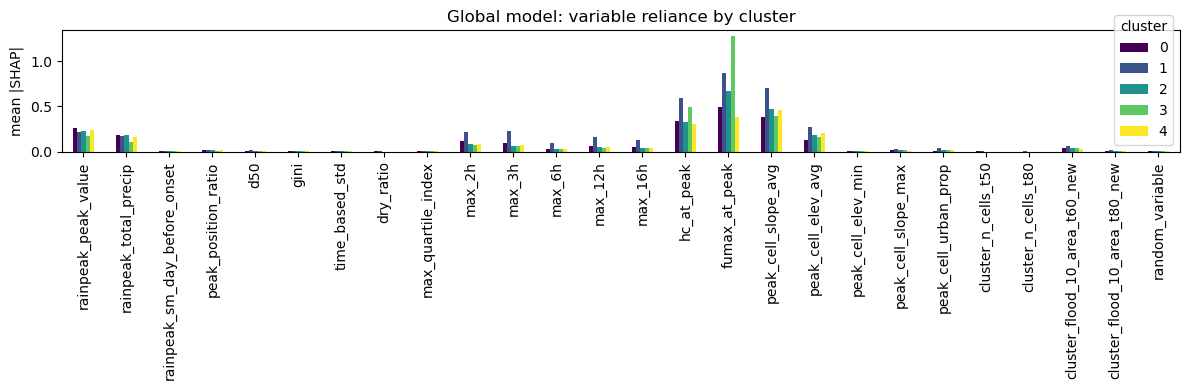

In [24]:
explainer = shap.TreeExplainer(rf_all)
sv = explainer.shap_values(X_all)    # all events: we are explaining the model, not testing it
sv_df = pd.DataFrame(sv, columns=X_all.columns, index=X_all.index)

# Mean |SHAP| per variable per cluster (in units of the target)
mean_abs = sv_df.abs().groupby(data['cluster']).mean()
print(mean_abs.round(3))

mean_abs[rain_vars + phys_vars].T.plot.bar(figsize=(12, 4), color=[cluster_colour[c] for c in mean_abs.index])
plt.ylabel('mean |SHAP|'); plt.title('Global model: variable reliance by cluster')
plt.tight_layout(); plt.show()

### 3. Response curves per cluster

Two versions, which should broadly agree. The SHAP version shows the effect of a variable relative to the average. The partial-dependence (PD) version shows predicted flooding as that variable is varied.

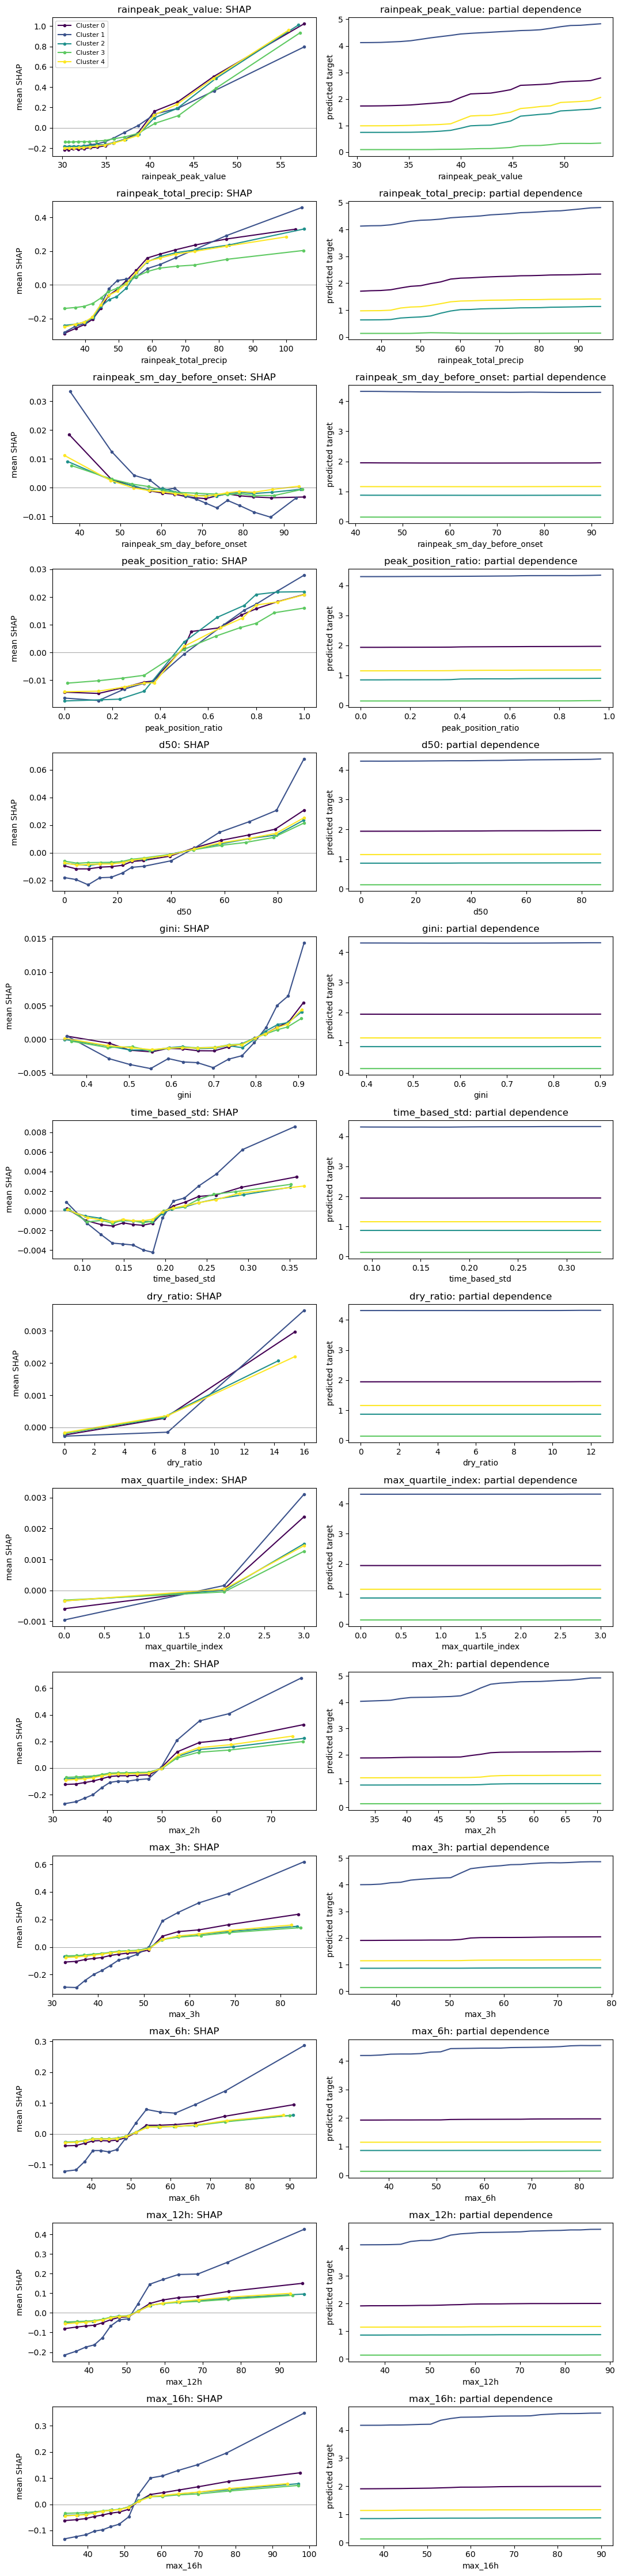

In [25]:
# --- (a) SHAP-based curves: mean SHAP in quantile bins of the feature, one line per cluster
def shap_curves_by_cluster(feature, n_bins=15, min_n=30, ax=None):
    ax = ax or plt.gca()
    d = pd.DataFrame({'x': X_all[feature], 'shap': sv_df[feature],
                      'cluster': data['cluster']})
    d['bin'] = pd.qcut(d['x'], q=n_bins, duplicates='drop')      # same bins for all clusters
    g = (d.groupby(['cluster', 'bin'], observed=True)
           .agg(x=('x', 'median'), shap=('shap', 'mean'), n=('x', 'size'))
           .reset_index())
    g = g[g['n'] >= min_n]                                       # drop thinly populated bins
    for c, gc in g.groupby('cluster'):
        ax.plot(gc['x'], gc['shap'], marker='o', ms=3, color=cluster_colour[c], label=f'Cluster {c}')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_xlabel(feature); ax.set_ylabel('mean SHAP')

# --- (b) Partial dependence evaluated on each cluster's own events
def pd_curve(model, Xc, feature, grid, max_n=1000, seed=0):
    Xs = Xc.sample(min(max_n, len(Xc)), random_state=seed).copy()
    out = []
    for v in grid:
        Xs[feature] = v
        out.append(model.predict(Xs).mean())
    return np.array(out)

def pd_curves_by_cluster(feature, ax=None, n_grid=25):
    ax = ax or plt.gca()
    grid = np.linspace(*np.percentile(X_all[feature], [5, 95]), n_grid)
    for c in sorted(data['cluster'].unique()):
        Xc = X_all[data['cluster'] == c]
        ax.plot(grid, pd_curve(rf_all, Xc, feature, grid), color=cluster_colour[c], label=f'Cluster {c}')
    ax.set_xlabel(feature); ax.set_ylabel('predicted target')

# One row per rainfall variable: SHAP curves | PD curves
fig, axs = plt.subplots(len(rain_vars), 2, figsize=(11, 3.2 * len(rain_vars)), squeeze=False)
for i, v in enumerate(rain_vars):
    shap_curves_by_cluster(v, ax=axs[i, 0]); axs[i, 0].set_title(f'{v}: SHAP')
    pd_curves_by_cluster(v, ax=axs[i, 1]);   axs[i, 1].set_title(f'{v}: partial dependence')
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

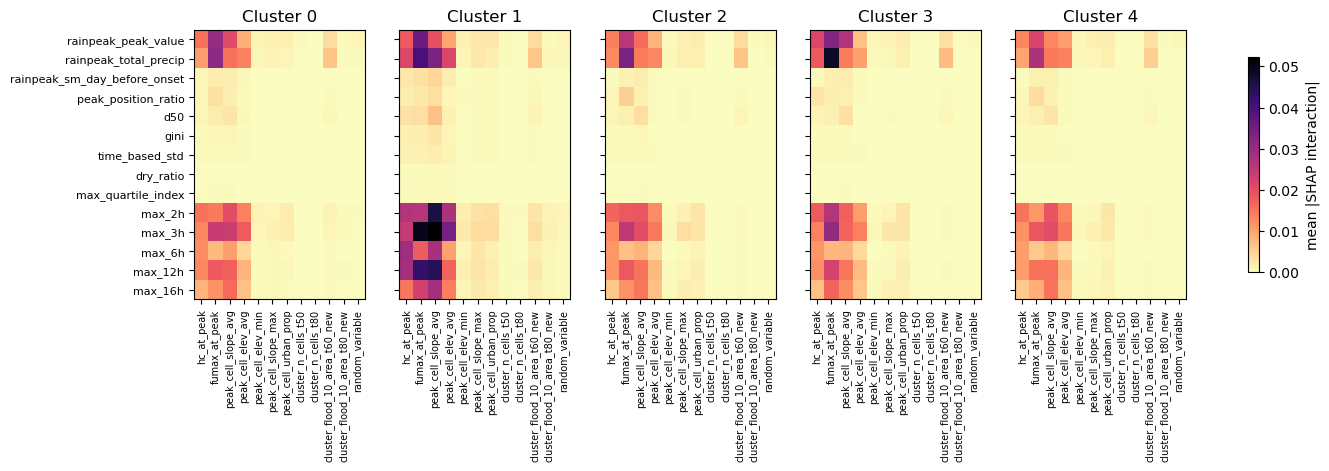

cluster                          0     1     2     3     4
variable                                                  
d50                           0.54  0.67  0.56  0.55  0.54
dry_ratio                     0.70  0.75  0.65  0.64  0.65
gini                          0.69  0.78  0.63  0.61  0.63
max_12h                       0.53  0.68  0.51  0.52  0.50
max_16h                       0.53  0.63  0.52  0.53  0.50
max_2h                        0.47  0.59  0.48  0.51  0.45
max_3h                        0.53  0.65  0.52  0.53  0.50
max_6h                        0.55  0.71  0.52  0.53  0.52
max_quartile_index            0.69  0.75  0.72  0.70  0.69
peak_position_ratio           0.53  0.60  0.60  0.52  0.53
rainpeak_peak_value           0.39  0.41  0.37  0.43  0.35
rainpeak_sm_day_before_onset  0.71  0.77  0.73  0.73  0.68
rainpeak_total_precip         0.48  0.56  0.47  0.50  0.45
time_based_std                0.67  0.77  0.63  0.61  0.63


In [26]:
def interaction_by_cluster(model, X, clusters, n_per_cluster=1500, seed=0):
    expl = shap.TreeExplainer(model)
    out = {}
    for c in sorted(clusters.unique()):
        Xc = X[clusters == c]
        Xc = Xc.sample(min(n_per_cluster, len(Xc)), random_state=seed)
        iv = expl.shap_interaction_values(Xc)                    # (n, p, p)
        out[c] = pd.DataFrame(np.abs(iv).mean(axis=0), index=X.columns, columns=X.columns)
    return out

inter = interaction_by_cluster(rf_all, X_all, data['cluster'])

# Heatmaps: rainfall variables (rows) x physical variables (columns), shared colour scale
vmax = max(m.loc[rain_vars, phys_vars].values.max() for m in inter.values())
fig, axs = plt.subplots(1, k, figsize=(3.2 * k, 3.5), sharey=True, squeeze=False)
for ax, (c, m) in zip(axs[0], inter.items()):
    im = ax.imshow(m.loc[rain_vars, phys_vars], vmin=0, vmax=vmax, cmap='magma_r', aspect='auto')
    ax.set_xticks(range(len(phys_vars))); ax.set_xticklabels(phys_vars, rotation=90, fontsize=7)
    ax.set_yticks(range(len(rain_vars))); ax.set_yticklabels(rain_vars, fontsize=8)
    ax.set_title(f'Cluster {c}')
fig.colorbar(im, ax=axs, label='mean |SHAP interaction|', shrink=0.8)
plt.show()

# Summary: how much of each rainfall variable's effect depends on physical setting?
rows = []
for c, m in inter.items():
    for r in rain_vars:
        rows.append(dict(cluster=c, variable=r,
                         main_effect=m.loc[r, r],
                         interaction_with_physical=m.loc[r, phys_vars].sum() * 2))  # x2: matrix is split symmetrically
summary = pd.DataFrame(rows)
summary['interaction_share'] = summary['interaction_with_physical'] / (summary['main_effect'] + summary['interaction_with_physical'])
print(summary.pivot(index='variable', columns='cluster', values='interaction_share').round(2))

In [30]:
short_events = subset_early[subset_early['length_of_active_rain'] < 20]
print(len(short_events), len(subset_early))

17255 20781


In [39]:
data  = short_events.copy()
X_all = data[predictor_variables]
y_all = data[TARGET].values
groups = ((data['rainpeak_x_coord'] // block).astype(int).astype(str) + '_' +
          (data['rainpeak_y_coord'] // block).astype(int).astype(str))

In [40]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from scipy.stats import spearmanr

shape_vars = ['peak_position_ratio', 'd50', 'gini', 'time_based_std', 'dry_ratio', 'max_quartile_index']
controls   = [v for v in predictor_variables if v not in shape_vars + ['random_variable']]

gkf = GroupKFold(n_splits=5)            # `groups` = your spatial blocks from earlier
rf_kw = dict(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0)

def oof(X, y):
    return cross_val_predict(RandomForestRegressor(**rf_kw), X, y, groups=groups, cv=gkf)

y = np.log1p(y_all)                     # optional: relative rather than absolute effects (if target >= 0)
y_res = y - oof(data[controls], y)

rows = []
for v in shape_vars + ['random_variable']:          # random_variable = null reference
    t_res = data[v].values - oof(data[controls], data[v].values)
    for c in sorted(data['cluster'].unique()):
        m = (data['cluster'] == c).values
        rho, _ = spearmanr(t_res[m], y_res[m])
        rows.append(dict(variable=v, cluster=c, rho=rho))
    rho_all, _ = spearmanr(t_res, y_res)
    rows.append(dict(variable=v, cluster='all', rho=rho_all))

print(pd.DataFrame(rows).pivot(index='variable', columns='cluster', values='rho').round(3))

17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
17255
cluster                  0      1      2      3      4    all
variable                                                     
d50                  0.129  0.121  0.188  0.127  0.129  0.129
dry_ratio           -0.007 -0.039  0.019  0.023  0.006 -0.014
gini                 0.007  0.018 -0.013 -0.043 -0.001  0.006
max_quartile_index   0.123  0.088  0.196  0.115  0.103  0.111
peak_position_ratio  0.140  0.131  0.220  0.147  0.151  0.143
random_variable     -0.017 -0.004 -0.037 -0.022 -0.010 -0.013
time_based_std       0.018 -0.014  0.005  0.068  0.008  0.005


In [27]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from scipy.stats import spearmanr

shape_vars = ['peak_position_ratio', 'd50', 'gini', 'time_based_std', 'dry_ratio', 'max_quartile_index']
controls   = [v for v in predictor_variables if v not in shape_vars + ['random_variable']]

gkf = GroupKFold(n_splits=5)            # `groups` = your spatial blocks from earlier
rf_kw = dict(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0)

def oof(X, y):
    return cross_val_predict(RandomForestRegressor(**rf_kw), X, y, groups=groups, cv=gkf)

y = np.log1p(y_all)                     # optional: relative rather than absolute effects (if target >= 0)
y_res = y - oof(data[controls], y)

rows = []
for v in shape_vars + ['random_variable']:          # random_variable = null reference
    t_res = data[v].values - oof(data[controls], data[v].values)
    for c in sorted(data['cluster'].unique()):
        m = (data['cluster'] == c).values
        rho, _ = spearmanr(t_res[m], y_res[m])
        rows.append(dict(variable=v, cluster=c, rho=rho))
    rho_all, _ = spearmanr(t_res, y_res)
    rows.append(dict(variable=v, cluster='all', rho=rho_all))

print(pd.DataFrame(rows).pivot(index='variable', columns='cluster', values='rho').round(3))

cluster                  0      1      2      3      4    all
variable                                                     
d50                  0.175  0.134  0.236  0.151  0.174  0.163
dry_ratio           -0.004 -0.044 -0.026  0.016 -0.015 -0.020
gini                 0.003  0.017 -0.031 -0.046 -0.006  0.002
max_quartile_index   0.167  0.106  0.251  0.155  0.156  0.148
peak_position_ratio  0.180  0.142  0.268  0.172  0.194  0.174
random_variable     -0.012 -0.003 -0.034  0.003 -0.021 -0.013
time_based_std       0.020 -0.006  0.014  0.003  0.015  0.009


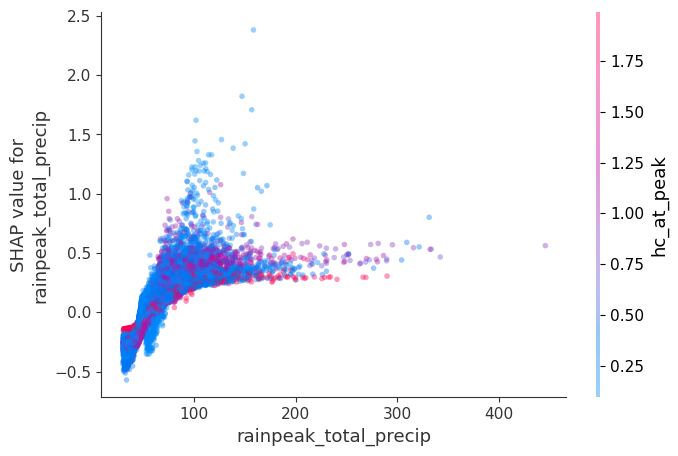

In [12]:
shap.dependence_plot('rainpeak_total_precip', sv, X_all, interaction_index='hc_at_peak', alpha=0.4)  # your variable names

### Things to test:
1. Remove Scotland

In [3]:
# subset_early = subset_early[subset_early['10cm_area']>0.05]

2. Remove zero flooding

In [4]:
# subset_early = subset_early[subset_early['y_coord'] < 560000]

3. Remove events only one timestep long

In [5]:
# subset_early = subset_early[subset_early['length_of_active_rain']>1].copy()

### How to make this work with prop_floodable_area_flooded? 
Would need the same metric in the surroudning cells potentially?
Actually, 

In [8]:
subset_early['cluster_flood_10_area_t80_new'] = subset_early['cluster_flood_10_area_t80'] - subset_early['rainpeak_10cm_area']
subset_early['cluster_flood_10_area_t60_new'] = subset_early['cluster_flood_10_area_t60'] - subset_early['rainpeak_10cm_area']

### 1. Define variables

--------------------------------------------------
###  2. Identify grouped and individual predictors
--------------------------------------------------

In [8]:
# variable_groups = {'Soil Saturation': ['sat_at_peak_new', 'sat_at_peak_old','fu_at_peak_new', 'rainpeak_sm_day_before_onset'],
#                     'Cell slope': ['peak_cell_slope_avg', 'peak_cell_slope_max'],
#                    'Cell capacity to hold water': ['hc_at_peak', 'fumax_at_peak', 'peak_cell_urban_prop'],
#                 'Rainfall temporal profile': ['peak_position_ratio', 'd50', 'max_quartile_index']}

In [9]:
corr = subset_early[predictor_variables].corr(method="spearman")   # your existing line
THRESH = 0.65   

groups = groups_hierarchical(corr, THRESH, method="average")
multi = {k: v for k, v in groups.items() if len(v) > 1}

# Fill this in from printing multi
label_map = {
    "G10": "Total rainfall",    
    "G5": "Cell capacity",
#     "G9": "Cell saturation",
    "G7": "Temporal loading",
    "G4":"Cell slope",
    "G3": "Cell elevation",
    "G2": 'Cluster_T50', "G1": 'Cluster_T80'
}

variable_groups = {label_map[k]: v for k, v in multi.items()}

In [10]:
grouped_variables = {col for cols in variable_groups.values() for col in cols}
individual_variables = [col for col in X.columns if col not in grouped_variables]

--------------------------------------------------
### 3. Create model instance
--------------------------------------------------

In [11]:
rf_all = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)

------------------------------------------------------------------------
### 4. Evaluate model performance using a train test split
------------------------------------------------------------------------

#### 4.a Split data into training and testing 

In [13]:
columns = subset_early.columns
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

#### 4.b Evaluate model performance 

MAE: 0.710 r2: 0.814


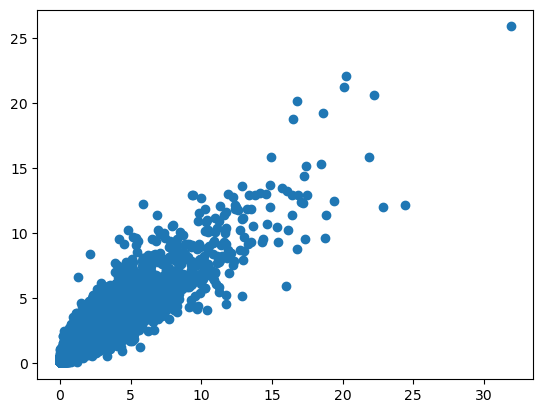

In [14]:
rf_all = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)

columns = subset_early.columns
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

rf_all.fit(X_train, y_train)
# Make predictions
y_pred = rf_all.predict(X_test)
# Evaluate predictions
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print('MAE: %.3f' % mae, 'r2: %.3f' % r2)

plt.scatter(y_test, y_pred) # 0.816 #0.757

In [ ]:
import shap
explainer = shap.TreeExplainer(rf_all)
sv = explainer.shap_values(X)          # X_all: predictors, aligned to subset_early
sv_df = pd.DataFrame(sv, columns=X.columns, index=X.index)
sv_df['cluster'] = subset_early['cluster']

mean_abs = sv_df.groupby('cluster').agg(lambda s: s.abs().mean())

#### 4.c. Evaluate feature importance using individual features

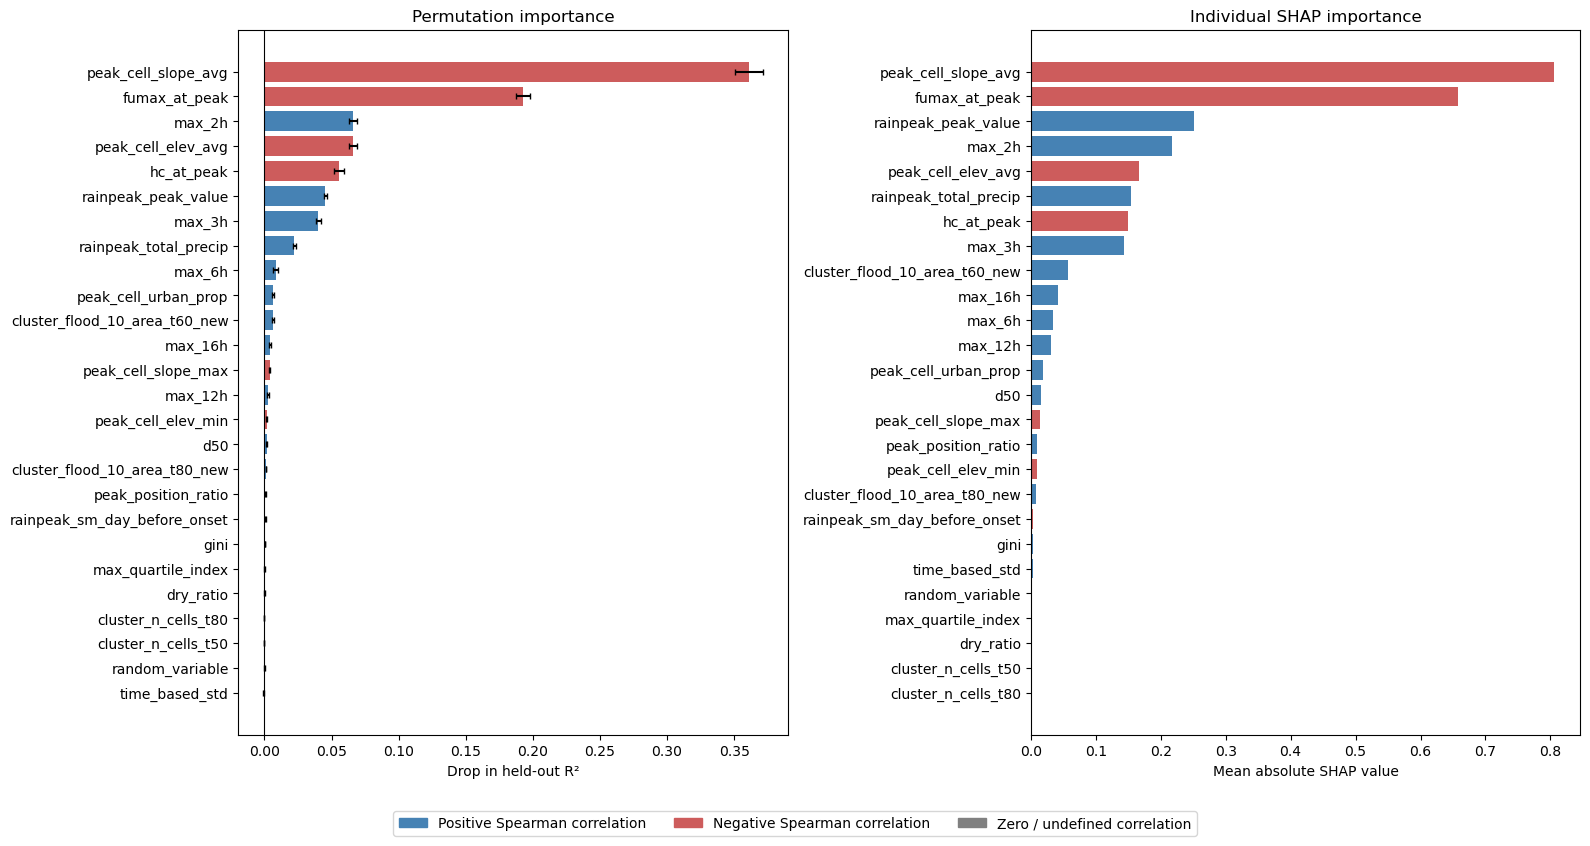

In [21]:
shap_results_individuals = shap_values_with_individual_predictors(X_test, rf_all, SEED, subset_size = None)    
pi_individual = permutation_importance_with_individual_predictors(X_test, y_test, rf_all, SEED)
predictor_corr_individual = find_correlations(subset_early, TARGET, pi_individual, variable_groups)
plot_importance_scores(pi_individual,shap_results_individuals.summary, predictor_corr_individual )

#### 4.d. Evaluate feature importance using grouped features

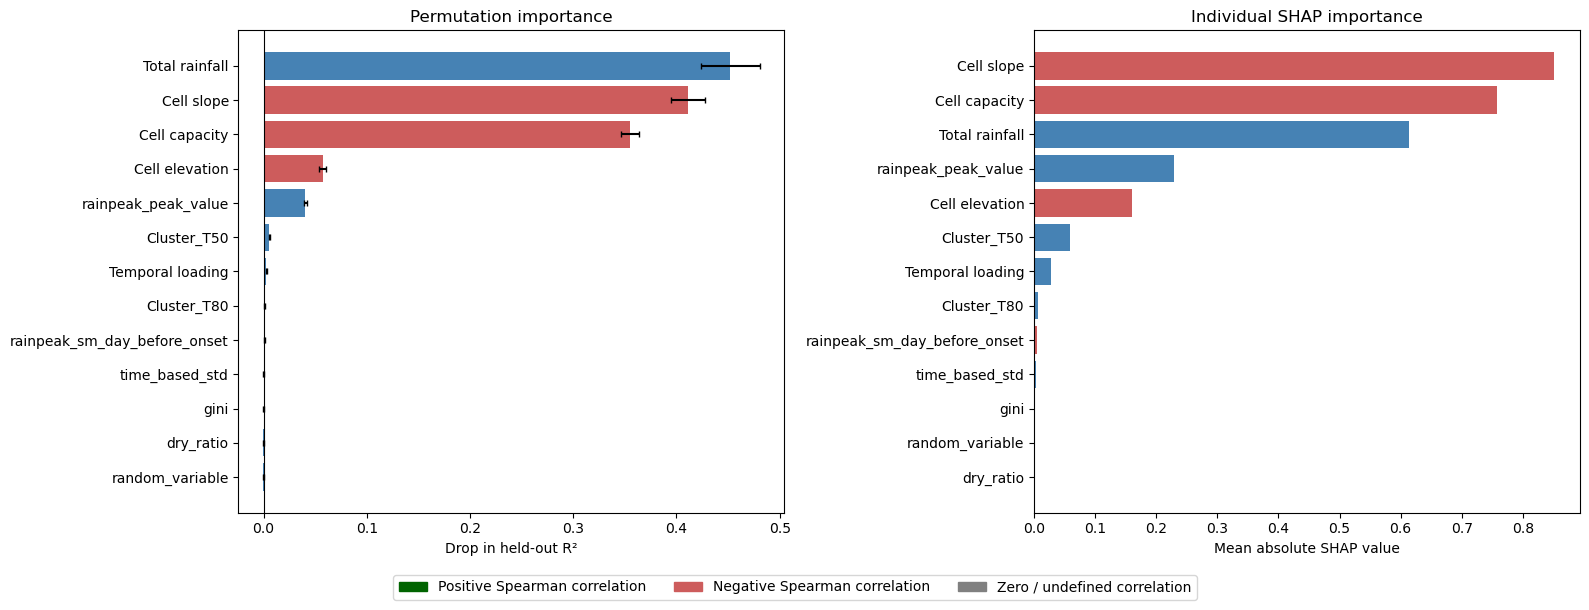

In [44]:
shap_results_groups = SHAP_values_with_groups(rf, X_test, individual_variables, variable_groups, SEED, subset_size = None)    
pi_groups = permutation_importance_with_groups(X_test, y_test, individual_variables,variable_groups,rf, SEED, n_repeats = 100)
predictor_corr_groups = find_correlations(subset_early, TARGET, pi_groups, variable_groups)
plot_importance_scores(pi_groups, shap_results_groups.summary, predictor_corr_groups )

#### 4.e. Evaluate feature importance using SHAP specific plots 

#### SHAP specific plots: Beeswarm plots

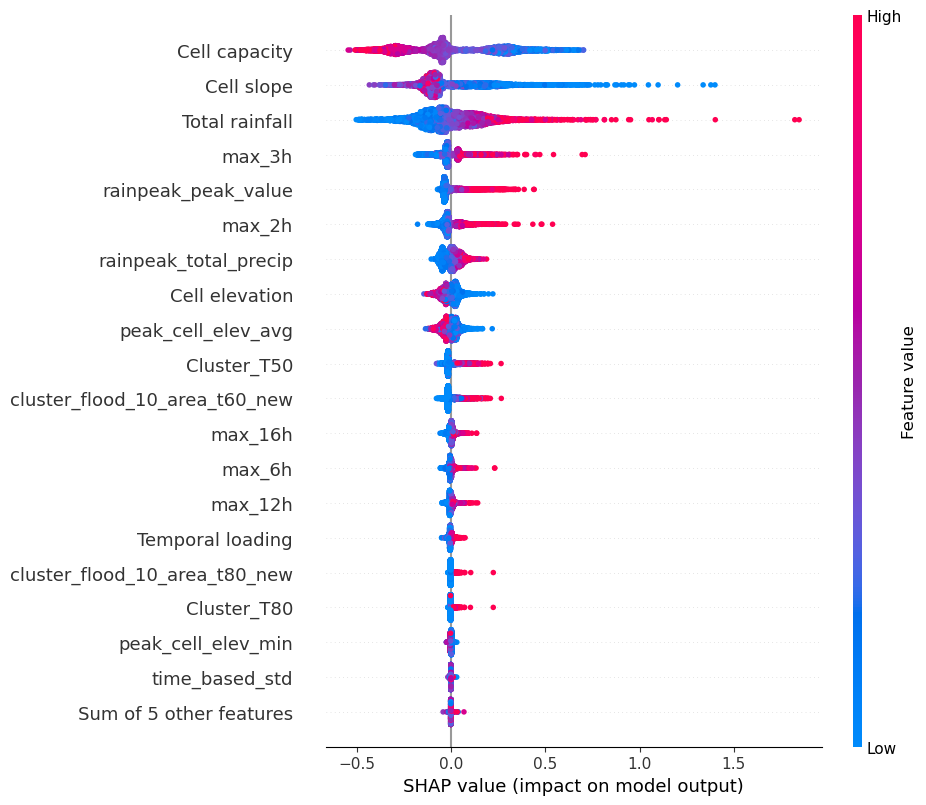

In [18]:
expl_all = make_grouped_explanation(shap_results_groups, variable_groups, individual_variables)
shap.plots.beeswarm(expl_all, max_display=20)

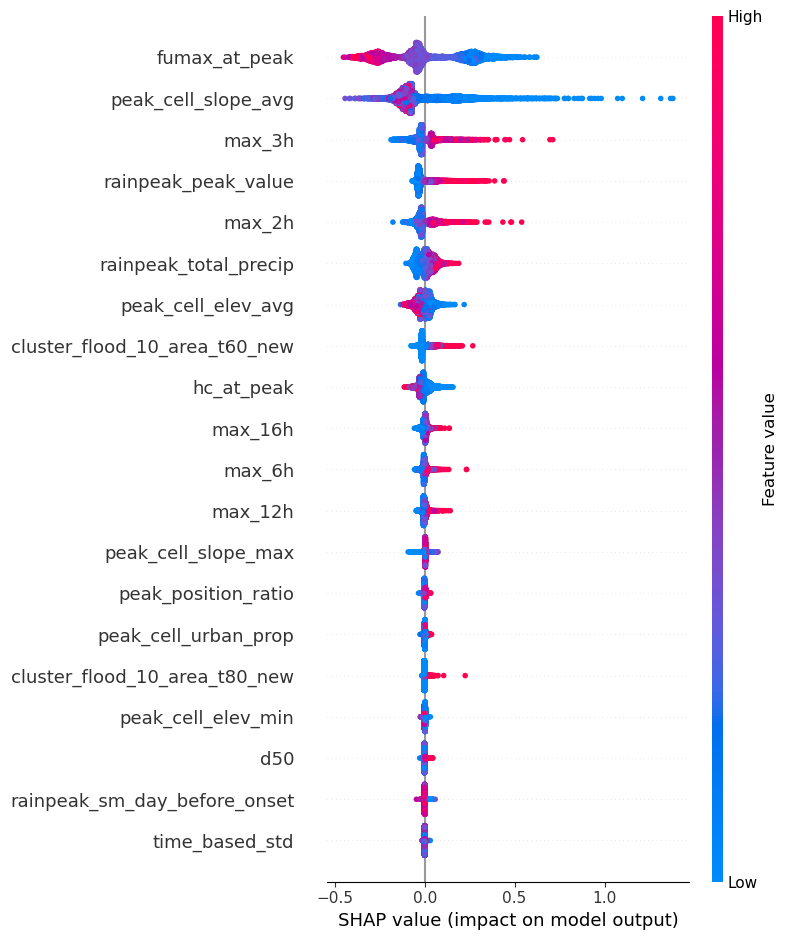

In [19]:
shap.summary_plot(shap_results_individuals.shap_values, shap_results_individuals.X_shap, show=True, max_display=20)

#### Other SHAP specific plots

Here we use SHAP functionalities to explore why some pixels get much less flooding than we'd expect them to

Waterfall plots:
- Waterfall plots are designed to display explanations for individual predictions. 
- The bottom of a waterfall plot starts as the expected value of the model output, and then each row shows how the positive (red) or negative (blue) contribution of each feature moves the value from the expected model output over the background dataset to the model output for this prediction.

Contrast values:
- Strongly negative: that driver pushes low pixels’ predictions down more than it does for rainfall-matched typical pixels. These are the candidate explanations for why those pixels respond so little.
- Near zero: the driver contributes about the same to both sets, so it doesn’t distinguish them.
- Positive: the driver pushes low pixels’ predictions up relative to typical pixels, i.e. it works against the low response (something else must be overpowering it).

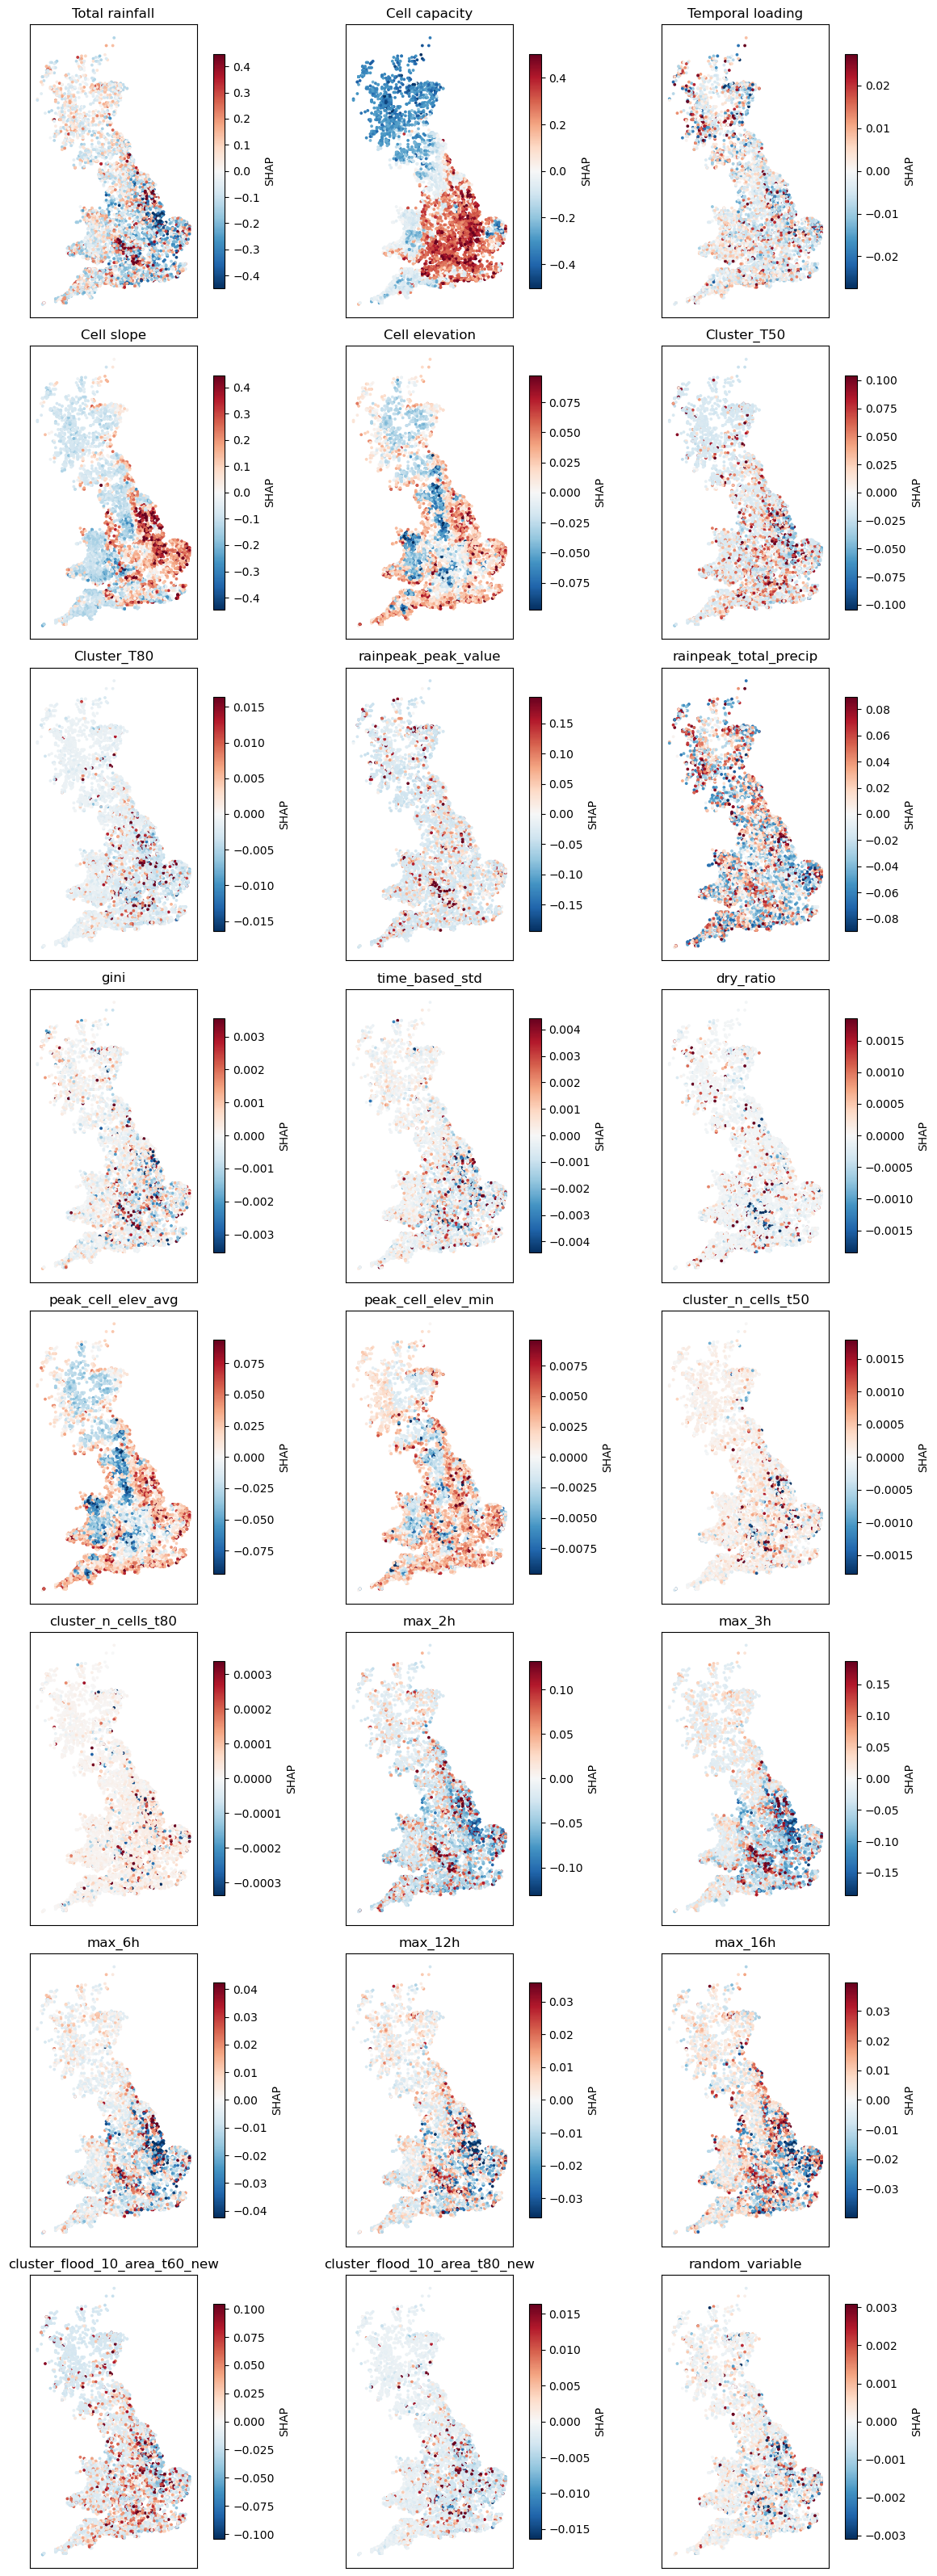

In [20]:
# Colour/data values for the waterfall: raw value for singletons, group summary for groups
grouped = pd.concat([shap_results_groups.group_shap_df, shap_results_groups.shap_df[individual_variables]], axis=1)

XCOL, YCOL = "rainpeak_x_coord", "rainpeak_y_coord"

# Coordinates for exactly the rows in `grouped`, in the same order
xy = subset_early.loc[grouped.index, [XCOL, YCOL]].to_numpy()

# All drivers, each with its own colour scale (shows the spatial pattern of every driver)
plot_shap_maps(grouped, xy)

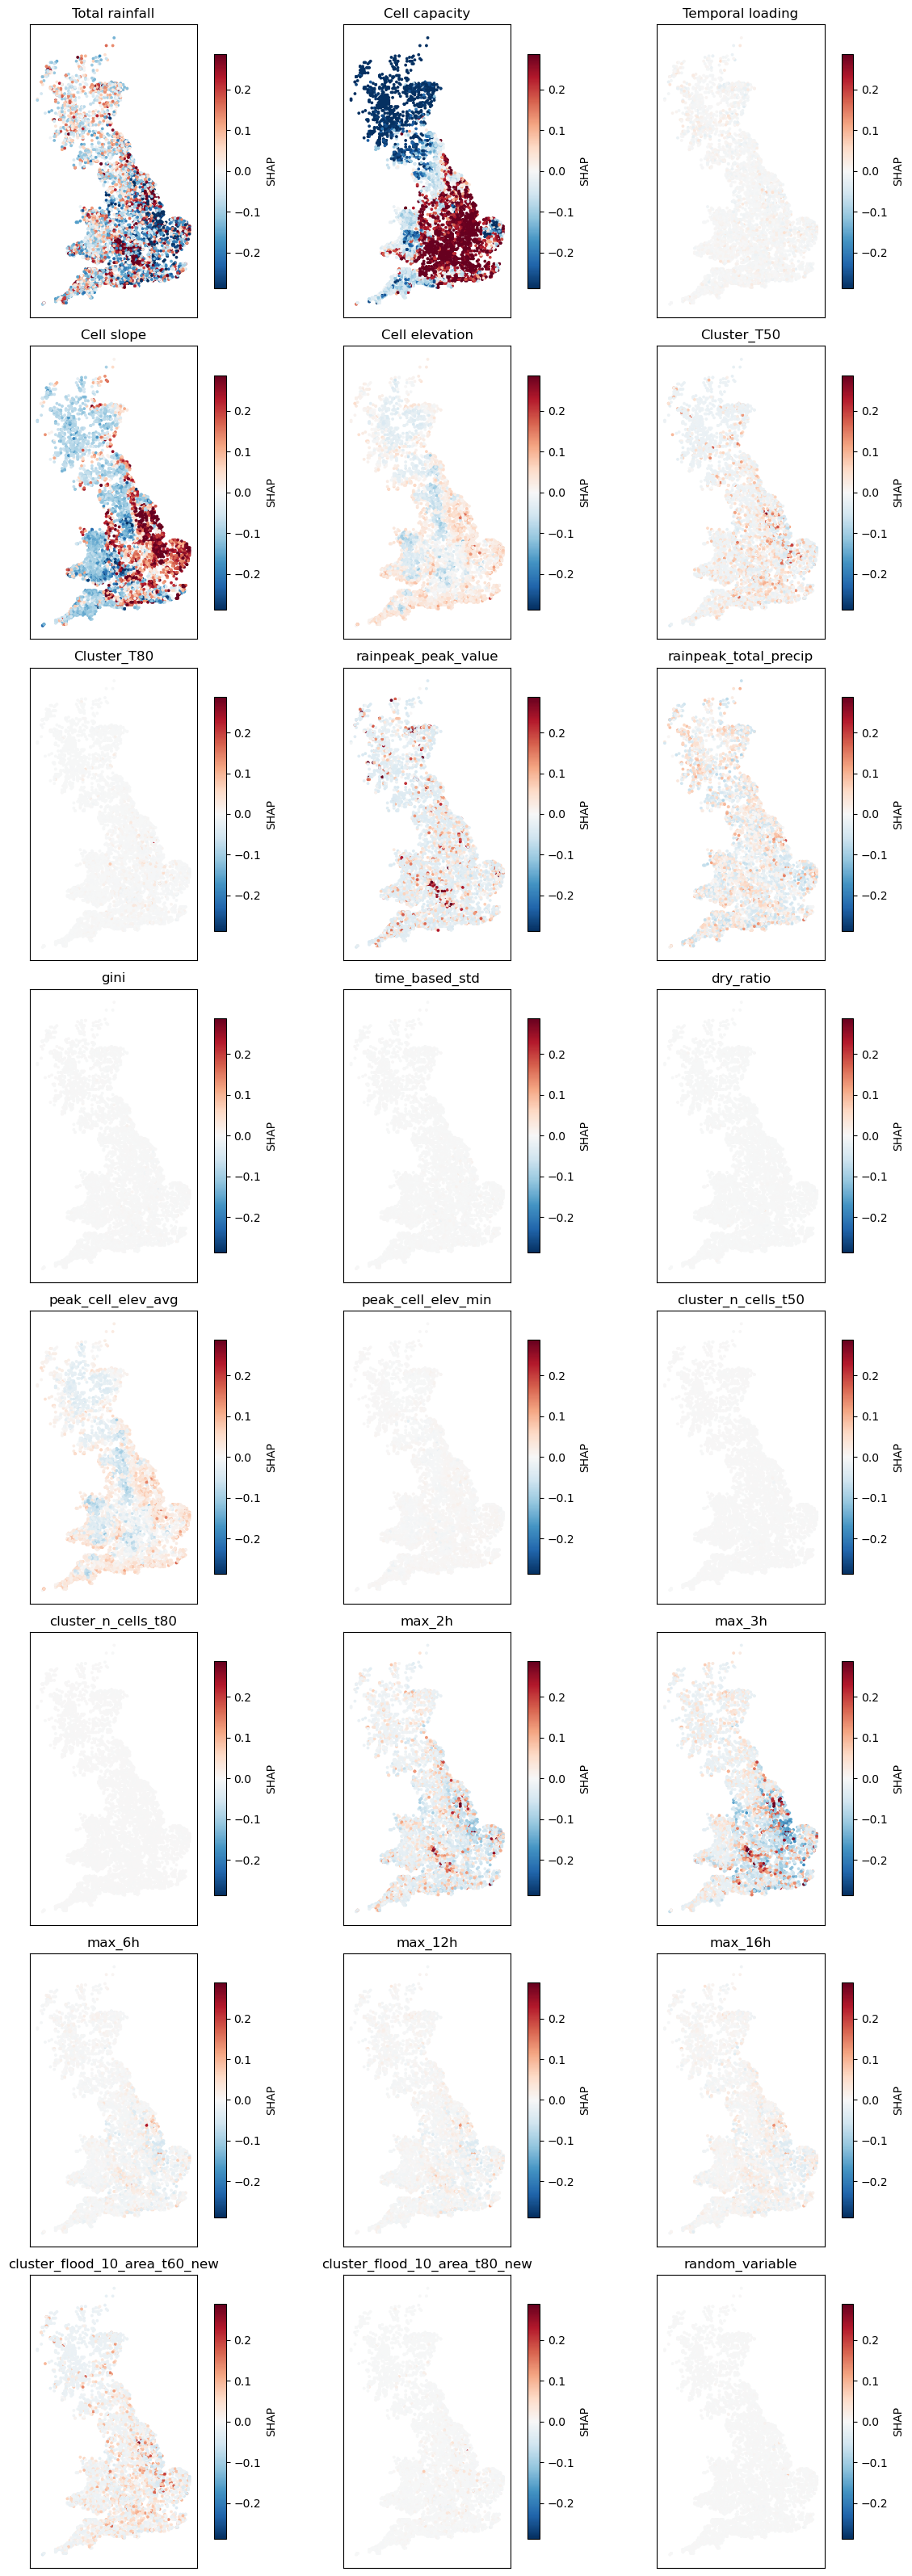

In [21]:
plot_shap_maps(grouped, xy, shared_scale=True)

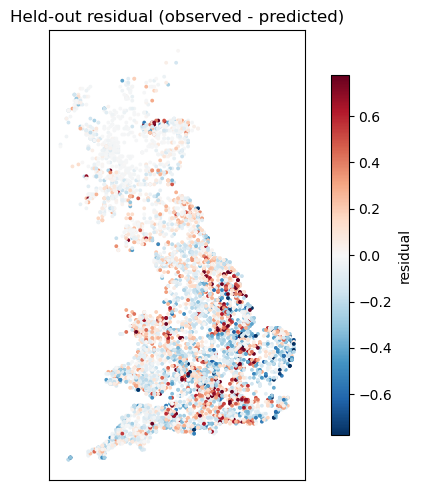

In [24]:
ys = pd.Series(np.asarray(y_test), index=X_test.index).loc[grouped.index]

resid = (ys - y_pred).loc[grouped.index]        # or (y - oof).loc[grouped.index]

lim = np.nanpercentile(np.abs(resid), 98)
fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=resid.to_numpy(), s=3,
                cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Held-out residual (observed - predicted)")
plt.colorbar(sc, ax=ax, shrink=0.8, label="residual")
plt.tight_layout(); plt.show()

### The single most influential driver per pixel:

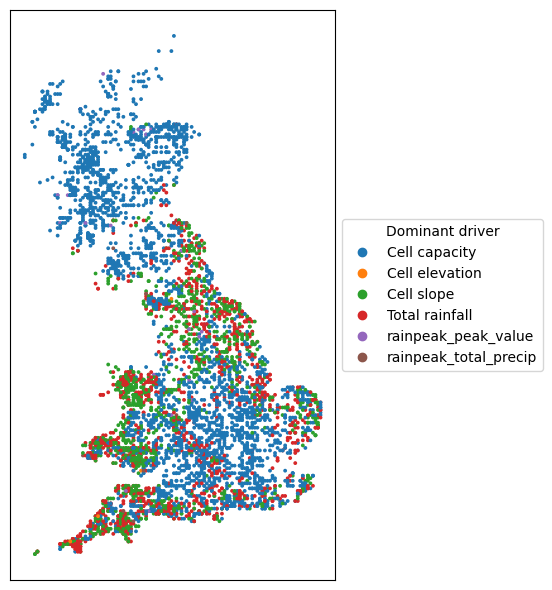

In [25]:
dominant = grouped.abs().idxmax(axis=1)
codes = dominant.astype("category")
cats = codes.cat.categories
n = len(cats)

cmap = plt.get_cmap("tab10" if n <= 10 else "tab20")
palette = [cmap(i) for i in range(n)]            # integer index -> the i-th colour exactly
point_colours = np.array(palette)[codes.cat.codes.to_numpy()]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xy[:, 0], xy[:, 1], c=point_colours, s=3)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

handles = [plt.Line2D([], [], marker="o", ls="", color=palette[i], label=c)
           for i, c in enumerate(cats)]
ax.legend(handles=handles, title="Dominant driver",
          loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

### Interaction plot

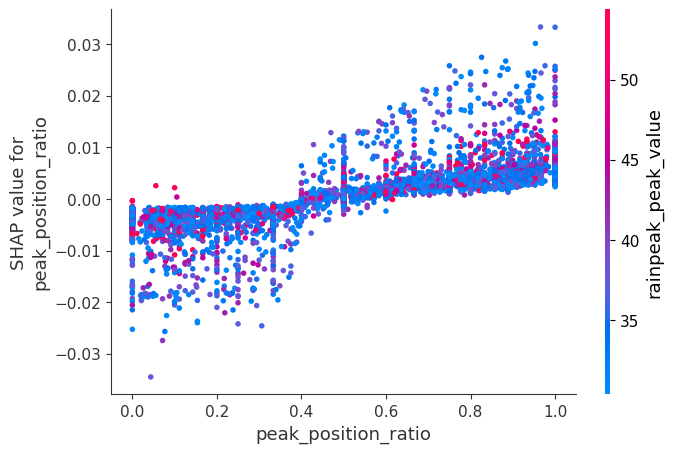

In [28]:
Xs = X.loc[grouped.index]
shap.dependence_plot("peak_position_ratio", shap_results_individuals.shap_df.values, Xs, interaction_index="rainpeak_peak_value")

------------------------------------
### EXPANSION: More complicated approaches for evaluating performance

1. Manual application of cross-validation:
    - This allows for construction of SHAP values and Permutation Importance within each fold
    - IT IS VERY SLOW!!

------------------------------------

In [31]:
cv_parameters = KFold(n_splits=5, shuffle=True, random_state=SEED)

list_shap_values, list_test_sets = [], []
fold_metrics, pi_records = [], []
pi_group_records = []        

for fold, (train_index, test_index) in enumerate(cv_parameters.split(X)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # --- fit ---
    t0 = time.perf_counter()
    clf = clone(rf).fit(X_train, y_train)
    t1 = time.perf_counter()

    # --- performance ---
    yhat = clf.predict(X_test)
    fold_metrics.append({"fold": fold,"r2": r2_score(y_test, yhat), "rmse": np.sqrt(mean_squared_error(y_test, yhat)),})

    # --- permutation importance ---
    t2 = time.perf_counter()
    pi = permutation_importance(clf, X_test, y_test, scoring="r2",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    pi_records.append(pd.DataFrame({"fold": fold, "predictor": X.columns, "PI_mean": pi.importances_mean, 
                                    "PI_sd": pi.importances_std,}))
    t3 = time.perf_counter()

    # --- SHAP ---
    sv = shap.TreeExplainer(clf).shap_values(X_test)
    list_shap_values.append(sv)
    list_test_sets.append(test_index)
    t4 = time.perf_counter()

    # ... inside the fold loop, after the SHAP step:
    pg = permutation_importance_with_groups(
        X_test, y_test, individual_variables, variable_groups,
        clf, SEED + fold, n_repeats=20)
    pg["fold"] = fold
    pi_group_records.append(pg)    

    print(f"fold {fold}: fit {t1-t0:.1f}s | PI {t3-t2:.1f}s | SHAP {t4-t3:.1f}s")


fold 0: fit 26.4s | PI 5.4s | SHAP 34.8s
fold 1: fit 26.0s | PI 4.3s | SHAP 35.1s
fold 2: fit 25.7s | PI 2.0s | SHAP 34.6s
fold 3: fit 25.8s | PI 2.0s | SHAP 34.6s
fold 4: fit 27.6s | PI 1.9s | SHAP 35.0s


In [32]:
# ---------- summaries ----------
metrics_df = pd.DataFrame(fold_metrics)
print(f"Full model R²: {metrics_df['r2'].mean():.4f} ± {metrics_df['r2'].std():.4f}")
print(f"Full model RMSE: {metrics_df['rmse'].mean():.4f}")

pi_all = pd.concat(pi_records, ignore_index=True)
pi_df = (pi_all.groupby("predictor")["PI_mean"]
               .agg(PI_mean="mean", PI_sd_across_folds="std")
               .sort_values("PI_mean", ascending=False))
pi_df.reset_index(inplace=True)
pi_df.rename(columns={'PI_sd_across_folds':'PI_sd'}, inplace=True)

pi_groups_all = pd.concat(pi_group_records, ignore_index=True)
pi_groups = (pi_groups_all.groupby("predictor")["PI_mean"].agg(PI_mean="mean", PI_sd="std")
             .sort_values("PI_mean", ascending=False).reset_index())

# SHAP reassembly as before
test_set = np.concatenate(list_test_sets)
shap_values_all = np.concatenate(list_shap_values, axis=0)
X_test_all = X.iloc[test_set]

shap_df = pd.DataFrame(shap_values_all, columns=X.columns, index=X.index[test_set])
shap_df = shap_df.loc[X.index]     
shap_df_summary = pd.DataFrame({"predictor": X.columns,
    "SHAP_mean_abs": shap_df.abs().mean().values}).sort_values("SHAP_mean_abs", ascending=False)

summary, group_shap_df = summarise_grouped_shap(shap_df, individual_variables, variable_groups)
shap_results_groups = ShapGroupResult(summary, shap_df, group_shap_df, X)

Full model R²: 0.7613 ± 0.0042
Full model RMSE: 0.2671


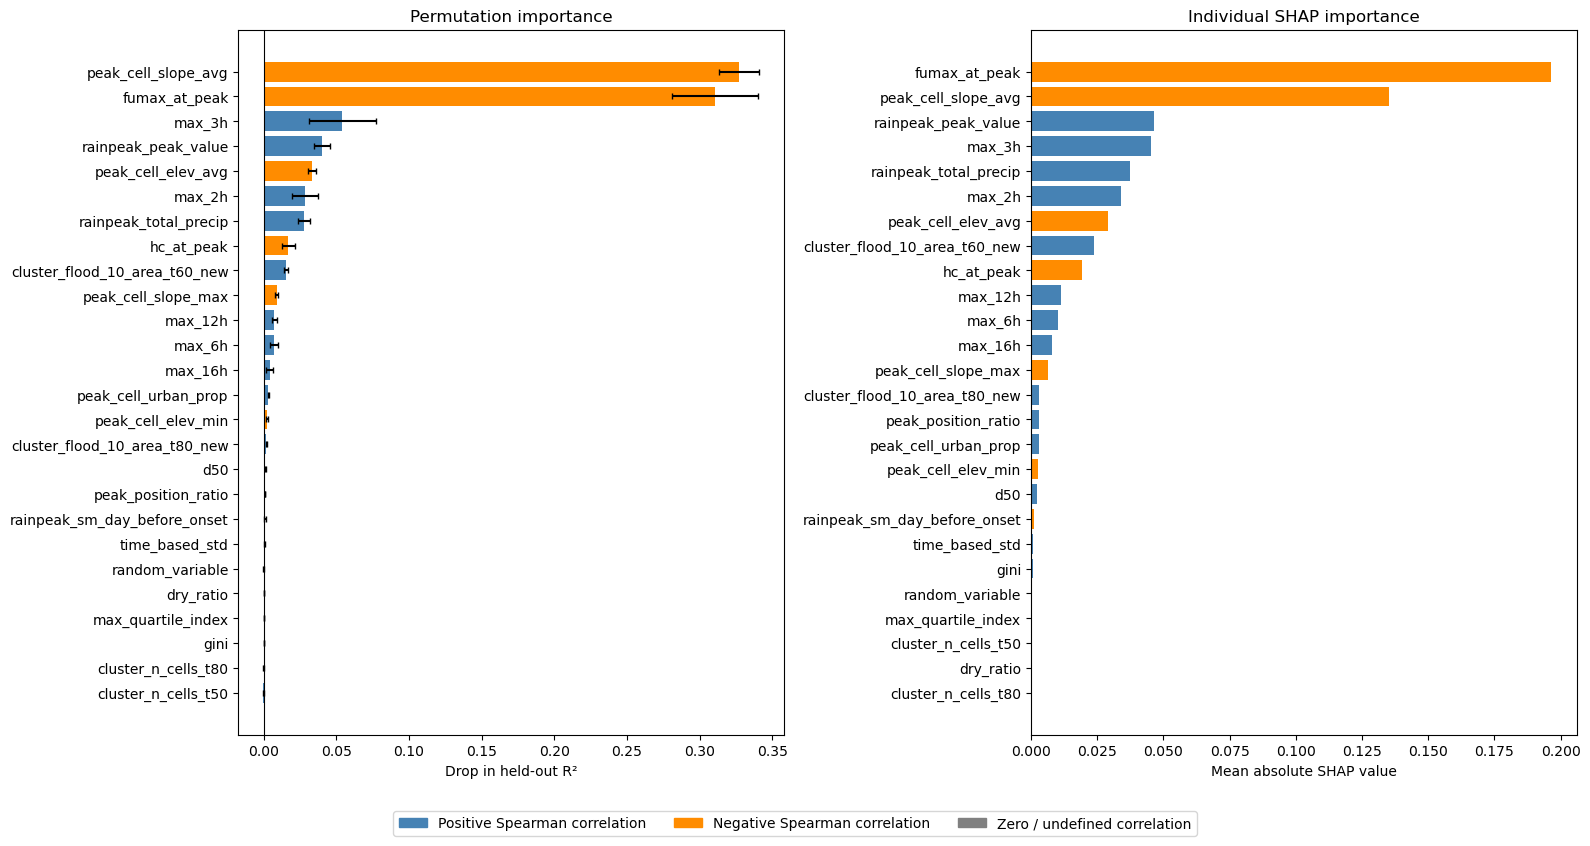

In [33]:
plot_importance_scores(pi_df, shap_df_summary, predictor_corr_individual )

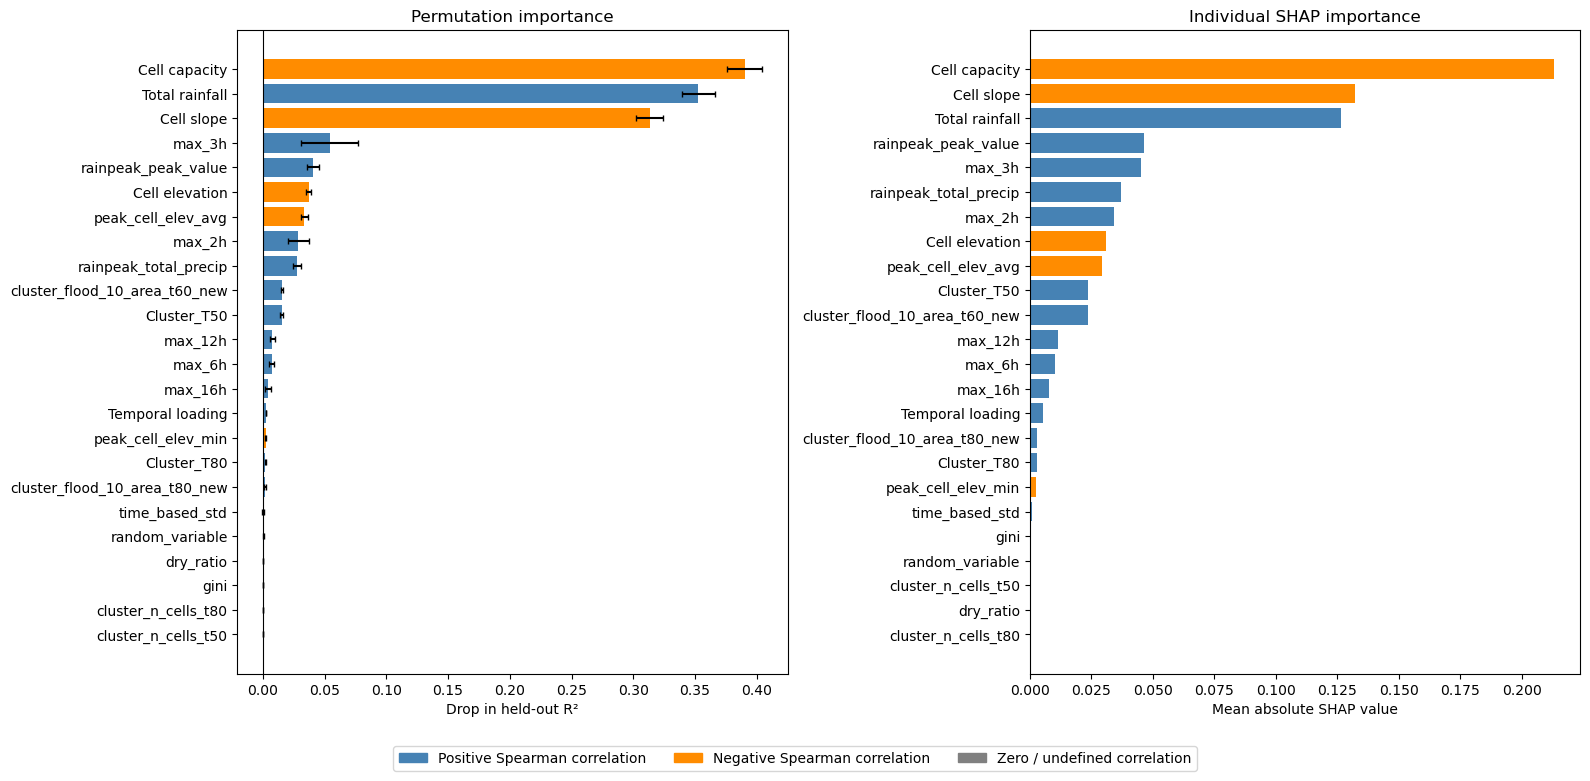

In [34]:
plot_importance_scores(pi_groups, shap_results_groups.summary, predictor_corr_groups )

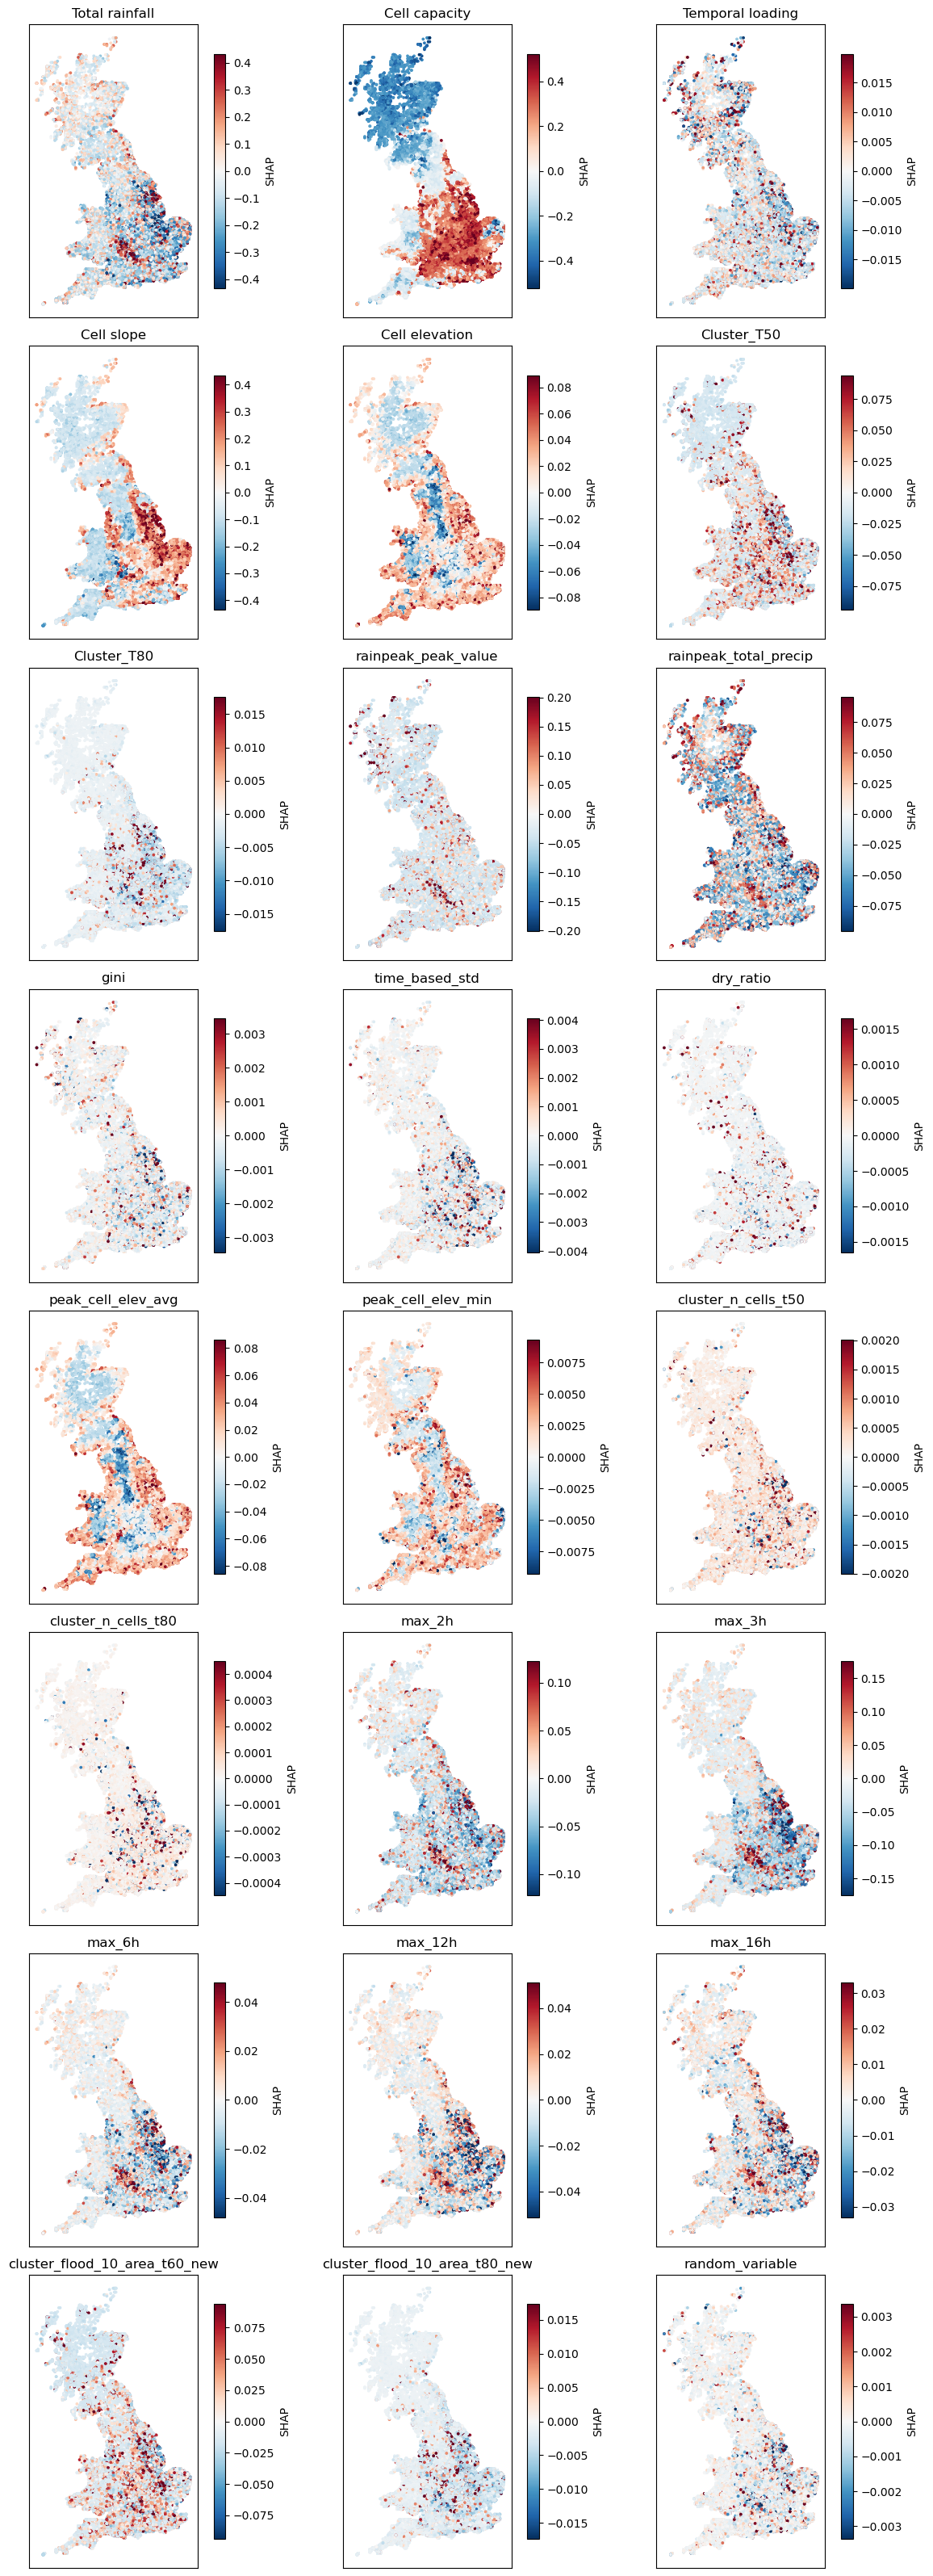

In [37]:
# Colour/data values for the waterfall: raw value for singletons, group summary for groups
grouped = pd.concat([shap_results_groups.group_shap_df, shap_results_groups.shap_df[individual_variables]], axis=1)

XCOL, YCOL = "rainpeak_x_coord", "rainpeak_y_coord"

# Coordinates for exactly the rows in `grouped`, in the same order
xy = subset_early.loc[grouped.index, [XCOL, YCOL]].to_numpy()

# All drivers, each with its own colour scale (shows the spatial pattern of every driver)
plot_shap_maps(grouped, xy)

In [ ]:
# from sklearn.inspection import PartialDependenceDisplay
# PartialDependenceDisplay.from_estimator(
# rf, X,
#     features=['hc_at_peak',
#               ('hc_at_peak', 'max_precip')],  # 2D interaction plot
#     kind='average')

------------------------------------
### EXPANSION: More complicated approaches for evaluating performance

2. Most complex application
    - Involves repeating the kfold CV process.  
    - Doesn't currently calculate the evaluation metrics or permutation importance.  
    - Decided it is probably overkill as even crazier SLOW

Based on : https://medium.com/data-science/using-shap-with-cross-validation-d24af548fadc

------------------------------------

In [ ]:
# for i, CV_repeat in enumerate(range(CV_repeats)): #-#-#
#     #Verbose 
#     print('\n------------ CV Repeat number:', CV_repeat)
#     #Establish CV scheme
#     CV = KFold(n_splits=5, shuffle=True, random_state=random_states[i]) # Set random state 

#     ix_training, ix_test = [], []
#     # Loop through each fold and append the training & test indices to the empty lists above
#     for fold in CV.split(X):
#         ix_training.append(fold[0]), ix_test.append(fold[1])
        
#     ## Loop through each outer fold and extract SHAP values 
#     for i, (train_outer_ix, test_outer_ix) in enumerate(zip(ix_training, ix_test)): 
#         #Verbose
#         print('\n------ Fold Number:',i)
#         X_train, X_test = X.iloc[train_outer_ix, :], X.iloc[test_outer_ix, :]
#         y_train, y_test = y.iloc[train_outer_ix], y.iloc[test_outer_ix]
        
#         model = RandomForestRegressor(random_state=10) # Random state for reproducibility (same results every time)
#         fit = model.fit(X_train, y_train)
#         yhat = fit.predict(X_test)
#         result = mean_squared_error(y_test, yhat)
#         print('RMSE:',round(np.sqrt(result),4))

#         # Use SHAP to explain predictions
#         explainer = shap.TreeExplainer(model)
#         shap_values = explainer.shap_values(X_test)

#         # Extract SHAP information per fold per sample 
#         for i, test_index in enumerate(test_outer_ix):
#             shap_values_per_cv[test_index][CV_repeat] = shap_values[i] #-#-#